In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [2]:
import pandas as pd
df = pd.read_csv("/content/drive/MyDrive/Test_dataset/NLP TM8/indonesiagelap_sentiment (1).xlsx - most_voted_sentiment-v1.csv")

In [3]:
!pip install sastrawi nltk

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 209.7/209.7 kB 6.3 MB/s eta 0:00:00


In [4]:
import re
import pandas as pd
from Sastrawi.Stemmer.StemmerFactory import StemmerFactory
from nltk.corpus import stopwords
import nltk

# Download stopwords
nltk.download('stopwords')
stopwords_id = set(stopwords.words('indonesian'))

# Inisialisasi stemmer
factory = StemmerFactory()
stemmer = factory.create_stemmer()

# Superscript unicode pattern
SUPERSCRIPT_PATTERN = r"[⁰¹²³⁴⁵⁶⁷⁸⁹⁺⁻⁽⁾ⁿ]"

# Kamus normalisasi kata informal → formal
alay_dict = {
    'ga': 'tidak',
    'gak': 'tidak',
    'nggak': 'tidak',
    'ngga': 'tidak',
    'gitu': 'begitu',
    'aja': 'saja',
    'yg': 'yang',
    'klo': 'kalau',
    'kalo': 'kalau',
    'dr': 'dari',
    'tp': 'tapi',
    'tdk': 'tidak',
    'blm': 'belum',
    'udh': 'sudah',
    'sdh': 'sudah',
    'sm': 'sama',
    'smua': 'semua',
    'dgn': 'dengan',
    'sy': 'saya',
    'gw': 'saya',
    'gue': 'saya',
    'lu': 'kamu',
    'lo': 'kamu'
    # tambahkan lebih banyak jika perlu
}

def normalize_alay(text):
    return " ".join([alay_dict.get(word, word) for word in text.split()])

def merge_particles(text):
    # Gabungkan partikel -nya, -ku, -mu yang terpisah
    text = re.sub(r'\b(\w+)\s+(nya|ku|mu)\b', r'\1\2', text)
    return text

def preprocess_tweet(text):
    if pd.isnull(text):
        return ""

    # Lowercase
    text = text.lower()

    # Hilangkan URL, mention, hashtag, superscript, simbol
    text = re.sub(r"http\S+|www\S+|pic.twitter.com\S+", "", text)
    text = re.sub(r"@\w+|#\w+", "", text)
    text = re.sub(SUPERSCRIPT_PATTERN, "", text)
    text = re.sub(r"[^a-zA-Z\s]", " ", text)
    text = re.sub(r"\s+", " ", text).strip()

    # Normalisasi kata informal
    text = normalize_alay(text)

    # Gabungkan partikel yang terpisah
    text = merge_particles(text)

    # Stemming
    text = stemmer.stem(text)

    # Stopword removal
    tokens = text.split()
    tokens = [word for word in tokens if word not in stopwords_id]

    return " ".join(tokens)

[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Unzipping corpora/stopwords.zip.


In [5]:
def preprocess_tweet_without_stem_stopword(text):
    if pd.isnull(text):
        return ""

    # Lowercase
    text = text.lower()

    # Hapus URL, mention, hashtag, superscript, simbol
    text = re.sub(r"http\S+|www\S+|pic.twitter.com\S+", "", text)
    text = re.sub(r"@\w+|#\w+", "", text)
    text = re.sub(SUPERSCRIPT_PATTERN, "", text)
    text = re.sub(r"[^a-zA-Z\s]", " ", text)
    text = re.sub(r"\s+", " ", text).strip()

    # Normalisasi kata informal
    text = normalize_alay(text)

    # Gabungkan partikel -nya, -ku, -mu
    text = merge_particles(text)

    return text

In [6]:
df_prepro = df.copy()

In [7]:
df_prepro['clean_text'] = df_prepro['full_text'].apply(preprocess_tweet)

In [8]:
df_prepro['clean_text_no_stem_stopword'] = df_prepro['full_text'].apply(preprocess_tweet_without_stem_stopword)

In [9]:
df_prepro.to_csv('df_prepro.csv', index=False)

In [10]:
df_prepro.head()

,id,full_text,final_sentiment,clean_text,clean_text_no_stem_stopword
0,0,@ARSIPAJA Menjijikan 3x Indonesia sampai punya...,negatif,jijik x indonesia presiden,menjijikan x indonesia sampai punya presiden b...
1,1,@ARSIPAJA Macan ompong prajurit cepirit kacung...,negatif,macan ompong prajurit cepirit kacung lancung,macan ompong prajurit cepirit kacung lancung
2,2,Rakyat seolah hanya dibuat permainan dan leluc...,negatif,rakyat olah main lelucon perintah,rakyat seolah hanya dibuat permainan dan leluc...
3,3,Duo Petaka Membawa Bencana #IndonesiaGelap,negatif,duo petaka bawa bencana,duo petaka membawa bencana
4,4,@krisiparuhbaya Poeeek mangg poeek literally #...,negatif,poeeek mangg poeek literally,poeeek mangg poeek literally


HYBRID SENTIMENT CLASSIFICATION: RNN + TRANSFORMER ATTENTION

[MODEL ADVANTAGES]
✓ RNN captures sequential dependencies and temporal patterns
✓ Transformer Attention captures global context and long-range dependencies
✓ Fusion of both approaches for improved performance

LOADING DATASET
Total data: 2157

DISTRIBUSI DATA AWAL
negatif: 1629 (75.5%)
netral: 347 (16.1%)
positif: 181 (8.4%)

Shape data setelah preprocessing: (2157, 100)

Ukuran data:
  Training: 1466
  Validation: 259
  Testing: 432

CLASS WEIGHTS CALCULATION

Distribusi kelas:
  positif: 145 (8.4%)
  negatif: 1303 (75.5%)
  netral: 277 (16.1%)

Class Weights (Automatic Balanced):
  positif: 3.9655
  negatif: 0.4413
  netral: 2.0758

Penjelasan:
  - Weight > 1.0 = Kelas minoritas (lebih penting)
  - Weight < 1.0 = Kelas mayoritas (kurang penting)
  - Weight ~ 1.0 = Kelas seimbang

[INFO] Building RNN branch...
[INFO] Building Transformer Attention branch...
[INFO] Fusing RNN and Attention outputs...
[INFO] Building classifi

/usr/local/lib/python3.12/dist-packages/keras/src/layers/layer.py:965: UserWarning: Layer 'positional_encoding' (of type PositionalEncoding) was passed an input with a mask attached to it. However, this layer does not support masking and will therefore destroy the mask information. Downstream layers will not see the mask.
  warnings.warn(


Model: "RNN_Transformer_Hybrid"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_text          │ (None, 100)       │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ embedding           │ (None, 100, 128)  │  1,024,000 │ input_text[0][0]  │
│ (Embedding)         │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ embedding_dropout   │ (None, 100, 128)  │          0 │ embedding[0][0]   │
│ (Dropout)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ not_equal           │ (None, 100)       │          0 │ input_text[0][0]  │
│ (NotEqual)          │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ bidirectional_rnn_1 │ (None, 100, 128)  │     24,704 │ embedding_dropou… │
│ (Bidirectional)     │                   │            │ not_equal[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ bidirectional_rnn_2 │ (None, 100, 64)   │     10,304 │ bidirectional_rn… │
│ (Bidirectional)     │                   │            │ not_equal[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ positional_encoding │ (None, 100, 64)   │          0 │ bidirectional_rn… │
│ (PositionalEncodin… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ multi_head_attenti… │ (None, 100, 64)   │     33,216 │ positional_encod… │
│ (MultiHeadAttentio… │                   │            │ positional_encod… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add (Add)           │ (None, 100, 64)   │          0 │ positional_encod… │
│                     │                   │            │ multi_head_atten… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ attention_layer_no… │ (None, 100, 64)   │        128 │ add[0][0]         │
│ (LayerNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ attention_dropout   │ (None, 100, 64)   │          0 │ attention_layer_… │
│ (Dropout)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ rnn_global_pool     │ (None, 64)        │          0 │ bidirectional_rn… │
│ (GlobalAveragePool… │                   │            │ not_equal[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ attention_global_p… │ (None, 64)        │          0 │ attention_dropou… │
│ (GlobalAveragePool… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ rnn_attention_fusi… │ (None, 128)       │          0 │ rnn_global_pool[… │
│ (Concatenate)       │                   │            │ attention_global… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ fusion_layer_norm   │ (None, 128)       │        256 │ rnn_attention_fu… │
│ (LayerNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_1 (Dense)     │ (None, 128)       │     16,512 │ fusion_layer_nor… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_1 (Dropout) │ (None, 128)       │          0 │ dense_1[0][0]     │
├─────────────────────┼───────────────────┼────────────┼─────────────────

 Total params: 1,117,571 (4.26 MB)

 Trainable params: 1,117,571 (4.26 MB)

 Non-trainable params: 0 (0.00 B)


TRAINING HYBRID MODEL: RNN + TRANSFORMER ATTENTION

Class weights yang digunakan:
  positif: 3.9655
  negatif: 0.4413
  netral: 2.0758
Epoch 1/50
46/46 - 35s - 753ms/step - accuracy: 0.3111 - loss: 1.2803 - val_accuracy: 0.1583 - val_loss: 1.1257 - learning_rate: 3.0000e-04
Epoch 2/50
46/46 - 2s - 37ms/step - accuracy: 0.2974 - loss: 1.1294 - val_accuracy: 0.7954 - val_loss: 0.9751 - learning_rate: 3.0000e-04
Epoch 3/50
46/46 - 2s - 53ms/step - accuracy: 0.3806 - loss: 1.0360 - val_accuracy: 0.6641 - val_loss: 0.8381 - learning_rate: 3.0000e-04
Epoch 4/50
46/46 - 2s - 34ms/step - accuracy: 0.5157 - loss: 0.9677 - val_accuracy: 0.6062 - val_loss: 0.8504 - learning_rate: 3.0000e-04
Epoch 5/50

Epoch 5:
  Train Loss: 0.9028, Train Acc: 0.5928
  Val Loss: 0.7614, Val Acc: 0.6718
46/46 - 2s - 34ms/step - accuracy: 0.5928 - loss: 0.9028 - val_accuracy: 0.6718 - val_loss: 0.7614 - learning_rate: 3.0000e-04
Epoch 6/50
46/46 - 2s - 34ms/step - accuracy: 0.6344 - loss: 0.7693 - val_accuracy: 0.

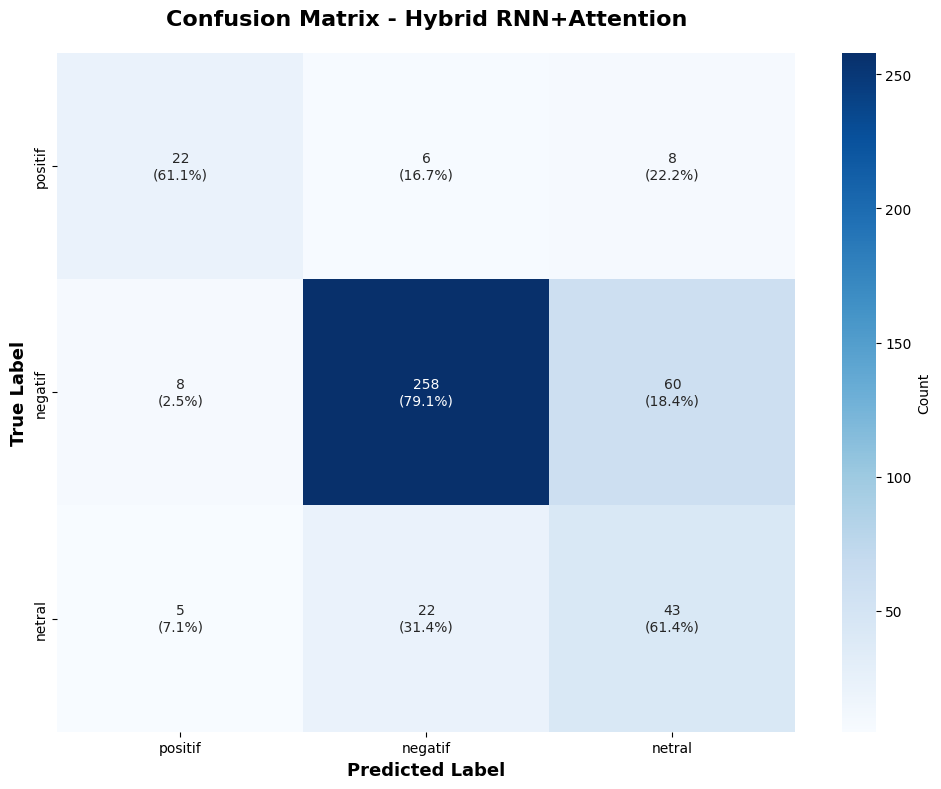


CONFUSION MATRIX DETAIL
 True \ Pred    Positif    Negatif     Netral      Total
------------------------------------------------------------
     positif         22          6          8         36
     negatif          8        258         60        326
      netral          5         22         43         70
------------------------------------------------------------
       Total         35        286        111        432

PER-CLASS METRICS
     Class    Precision       Recall     F1-Score
------------------------------------------------------------
   positif       62.86%       61.11%       61.97%
   negatif       90.21%       79.14%       84.31%
    netral       38.74%       61.43%       47.51%


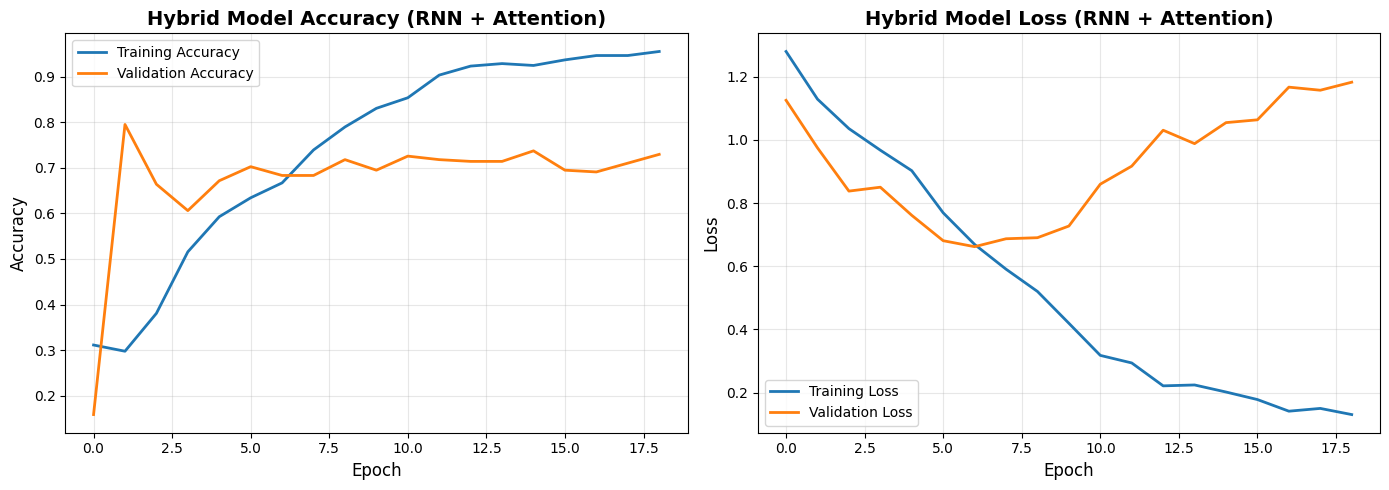


CONTOH PREDIKSI

1. Teks: pelayanan sangat memuaskan dan bagus sekali
   Prediksi: POSITIF
   Probabilitas:
      positif: 69.10%
      negatif: 9.32%
      netral: 21.57%
------------------------------------------------------------

2. Teks: produk jelek kualitas buruk mengecewakan
   Prediksi: NETRAL
   Probabilitas:
      positif: 6.74%
      negatif: 36.05%
      netral: 57.21%
------------------------------------------------------------

3. Teks: barang sudah sampai terima kasih
   Prediksi: NETRAL
   Probabilitas:
      positif: 10.93%
      negatif: 33.25%
      netral: 55.82%
------------------------------------------------------------

4. Teks: aplikasi sangat membantu dan mudah digunakan
   Prediksi: NETRAL
   Probabilitas:
      positif: 8.55%
      negatif: 34.10%
      netral: 57.36%
------------------------------------------------------------

5. Teks: pengiriman lambat tidak sesuai ekspektasi
   Prediksi: NETRAL
   Probabilitas:
      positif: 5.51%
      negatif: 45.91

In [ ]:
import numpy as np
import pandas as pd
import tensorflow as tf
from tensorflow.keras.models import Model
from tensorflow.keras.layers import (Input, Embedding, Dense, Dropout,
                                      LayerNormalization, SimpleRNN, Bidirectional,
                                      MultiHeadAttention, Concatenate, GlobalAveragePooling1D)
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences
from tensorflow.keras.utils import to_categorical
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix
from sklearn.utils.class_weight import compute_class_weight
import matplotlib.pyplot as plt
import seaborn as sns


class PositionalEncoding(tf.keras.layers.Layer):
    """
    Layer untuk menambahkan positional encoding pada input embeddings
    Membantu Transformer memahami urutan sequence
    """
    def __init__(self, max_length, embed_dim):
        super(PositionalEncoding, self).__init__()
        self.max_length = max_length
        self.embed_dim = embed_dim

    def get_angles(self, pos, i, embed_dim):
        angle_rates = 1 / np.power(10000, (2 * (i//2)) / np.float32(embed_dim))
        return pos * angle_rates

    def build(self, input_shape):
        # Get the actual embedding dimension from input shape
        actual_embed_dim = input_shape[-1]

        # Create positional encoding with the actual embedding dimension
        angle_rads = np.zeros((self.max_length, actual_embed_dim))

        for pos in range(self.max_length):
            for i in range(0, actual_embed_dim, 2):
                angle = pos / np.power(10000, (2 * i) / actual_embed_dim)
                angle_rads[pos, i] = np.sin(angle)
                if i + 1 < actual_embed_dim:
                    angle_rads[pos, i + 1] = np.cos(angle)

        pos_encoding = angle_rads[np.newaxis, ...]
        self.pos_encoding = tf.cast(pos_encoding, dtype=tf.float32)

        super().build(input_shape)

    def call(self, x):
        seq_len = tf.shape(x)[1]
        return x + self.pos_encoding[:, :seq_len, :]


class RNNWithTransformerAttention:
    def __init__(self, vocab_size=8000, embedding_dim=128, rnn_units=64, max_length=100,
                 num_attention_heads=4, use_bidirectional=True):
        """
        Inisialisasi Hybrid Model: RNN Enhanced with Transformer Attention

        Model ini menggabungkan:
        1. RNN untuk menangkap sequential dependencies
        2. Multi-Head Attention (dari Transformer) untuk menangkap global context

        Parameters:
        - vocab_size: Ukuran vocabulary
        - embedding_dim: Dimensi embedding
        - rnn_units: Jumlah units di RNN layer
        - max_length: Panjang maksimal sequence
        - num_attention_heads: Jumlah attention heads
        - use_bidirectional: Gunakan Bidirectional RNN atau tidak
        """
        self.vocab_size = vocab_size
        self.embedding_dim = embedding_dim
        self.rnn_units = rnn_units
        self.max_length = max_length
        self.num_attention_heads = num_attention_heads
        self.use_bidirectional = use_bidirectional
        self.tokenizer = None
        self.model = None
        self.class_weights = None
        self.label_encoder = {'positif': 0, 'negatif': 1, 'netral': 2}
        self.reverse_label_encoder = {0: 'positif', 1: 'negatif', 2: 'netral'}

    def build_model(self):
        """
        Membangun Hybrid Model: RNN + Transformer Attention

        Arsitektur:
        1. Embedding Layer
        2. Positional Encoding (untuk Attention)
        3. Bidirectional RNN layers (menangkap sequential patterns)
        4. Multi-Head Attention (menangkap global context)
        5. Kombinasi RNN output + Attention output
        6. Dense layers untuk klasifikasi
        """
        # Input layer
        inputs = Input(shape=(self.max_length,), dtype=tf.int32, name='input_text')

        # ===== EMBEDDING LAYER =====
        embedding = Embedding(
            input_dim=self.vocab_size,
            output_dim=self.embedding_dim,
            mask_zero=True,
            name='embedding'
        )(inputs)

        # Dropout setelah embedding
        x = Dropout(0.3, name='embedding_dropout')(embedding)

        # ===== RNN BRANCH =====
        # RNN menangkap sequential dependencies (temporal patterns)
        print("\n[INFO] Building RNN branch...")

        if self.use_bidirectional:
            # Bidirectional RNN layer pertama
            rnn_out1 = Bidirectional(
                SimpleRNN(
                    units=self.rnn_units,
                    return_sequences=True,
                    dropout=0.2,
                    recurrent_dropout=0.2,
                    name='rnn_layer_1'
                ),
                name='bidirectional_rnn_1'
            )(x)

            # Bidirectional RNN layer kedua
            rnn_out2 = Bidirectional(
                SimpleRNN(
                    units=self.rnn_units//2,
                    return_sequences=True,  # Return sequences untuk attention
                    dropout=0.2,
                    recurrent_dropout=0.2,
                    name='rnn_layer_2'
                ),
                name='bidirectional_rnn_2'
            )(rnn_out1)
        else:
            # Unidirectional RNN
            rnn_out1 = SimpleRNN(
                units=self.rnn_units,
                return_sequences=True,
                dropout=0.2,
                recurrent_dropout=0.2,
                name='rnn_layer_1'
            )(x)

            rnn_out2 = SimpleRNN(
                units=self.rnn_units//2,
                return_sequences=True,
                dropout=0.2,
                recurrent_dropout=0.2,
                name='rnn_layer_2'
            )(rnn_out1)

        # ===== POSITIONAL ENCODING FOR ATTENTION =====
        # Ditambahkan untuk membantu attention mechanism
        # Positional encoding needs to match RNN output dimension
        rnn_output_dim = self.rnn_units if not self.use_bidirectional else self.rnn_units * 2

        # Buat positional encoding yang kompatibel dengan RNN output
        pos_encoding_layer = PositionalEncoding(self.max_length, rnn_output_dim)
        pos_encoded = pos_encoding_layer(rnn_out2)

        # ===== TRANSFORMER ATTENTION BRANCH =====
        # Multi-Head Attention menangkap global context dan dependencies
        print("[INFO] Building Transformer Attention branch...")

        # rnn_output_dim sudah didefinisikan di atas

        # Multi-Head Self-Attention
        # Memungkinkan model untuk "attend" ke semua posisi dalam sequence
        # Pastikan key_dim adalah bilangan bulat positif
        key_dim = max(1, rnn_output_dim // self.num_attention_heads)
        attention_output = MultiHeadAttention(
            num_heads=self.num_attention_heads,
            key_dim=key_dim,
            dropout=0.1,
            name='multi_head_attention'
        )(pos_encoded, pos_encoded)

        # Add & Norm (Residual connection + Layer Normalization)
        attention_output = LayerNormalization(
            epsilon=1e-6,
            name='attention_layer_norm'
        )(pos_encoded + attention_output)

        # Dropout untuk regularisasi
        attention_output = Dropout(0.2, name='attention_dropout')(attention_output)

        # ===== FUSION: COMBINE RNN + ATTENTION =====
        print("[INFO] Fusing RNN and Attention outputs...")

        # Gunakan Global Average Pooling untuk kedua output sebelum concatenation
        # Ini memastikan dimensi yang konsisten
        rnn_pooled = GlobalAveragePooling1D(name='rnn_global_pool')(rnn_out2)
        attention_pooled = GlobalAveragePooling1D(name='attention_global_pool')(attention_output)

        # Concatenate pooled outputs
        combined = Concatenate(name='rnn_attention_fusion')([rnn_pooled, attention_pooled])

        # Layer Normalization setelah fusion
        combined = LayerNormalization(epsilon=1e-6, name='fusion_layer_norm')(combined)

        # ===== CLASSIFICATION LAYERS =====
        print("[INFO] Building classification layers...")

        # Dense layers dengan dropout untuk klasifikasi final
        dense1 = Dense(128, activation='relu', name='dense_1')(combined)
        dense1 = Dropout(0.4, name='dropout_1')(dense1)

        dense2 = Dense(64, activation='relu', name='dense_2')(dense1)
        dense2 = Dropout(0.3, name='dropout_2')(dense2)

        # Output layer untuk 3 kelas sentiment
        outputs = Dense(3, activation='softmax', name='output')(dense2)

        # ===== CREATE MODEL =====
        model = Model(inputs=inputs, outputs=outputs, name='RNN_Transformer_Hybrid')

        # Compile model
        model.compile(
            optimizer=tf.keras.optimizers.Adam(learning_rate=0.0003),
            loss='categorical_crossentropy',
            metrics=['accuracy']
        )

        self.model = model

        print("\n" + "="*70)
        print("HYBRID MODEL ARCHITECTURE: RNN + TRANSFORMER ATTENTION")
        print("="*70)
        print(f"Vocabulary Size: {self.vocab_size}")
        print(f"Embedding Dimension: {self.embedding_dim}")
        print(f"RNN Units: {self.rnn_units}")
        print(f"Bidirectional RNN: {self.use_bidirectional}")
        print(f"Max Sequence Length: {self.max_length}")
        print(f"Number of Attention Heads: {self.num_attention_heads}")
        print("\n[ARCHITECTURE COMPONENTS]")
        print("1. Embedding Layer → Text to dense vectors")
        print("2. Positional Encoding → Position information for attention")
        print("3. Bidirectional RNN (2 layers) → Sequential pattern learning")
        print("4. Multi-Head Attention → Global context capture")
        print("5. Fusion Layer → Combine RNN + Attention")
        print("6. Dense Layers → Classification")
        print("="*70)
        model.summary()

        return model

    def prepare_data(self, texts, labels):
        """
        Mempersiapkan data untuk training
        """
        # Tokenisasi teks
        self.tokenizer = Tokenizer(num_words=self.vocab_size, oov_token='<OOV>')
        self.tokenizer.fit_on_texts(texts)

        # Konversi teks ke sequence
        sequences = self.tokenizer.texts_to_sequences(texts)

        # Padding sequence
        padded_sequences = pad_sequences(sequences, maxlen=self.max_length,
                                        padding='post', truncating='post')

        # Konversi label ke encoded
        encoded_labels = np.array([self.label_encoder[label] for label in labels])

        # Konversi ke categorical
        categorical_labels = to_categorical(encoded_labels, num_classes=3)

        return padded_sequences, categorical_labels, encoded_labels

    def calculate_class_weights(self, y_encoded):
        """
        Menghitung class weights untuk menangani imbalanced data
        """
        print("\n" + "="*60)
        print("CLASS WEIGHTS CALCULATION")
        print("="*60)

        # Hitung distribusi kelas
        unique, counts = np.unique(y_encoded, return_counts=True)
        total = len(y_encoded)

        print("\nDistribusi kelas:")
        for cls, count in zip(unique, counts):
            percentage = (count/total)*100
            print(f"  {self.reverse_label_encoder[cls]}: {count} ({percentage:.1f}%)")

        # Hitung class weights
        class_weights_array = compute_class_weight(
            class_weight='balanced',
            classes=np.unique(y_encoded),
            y=y_encoded
        )

        # Konversi ke dictionary
        class_weights = {i: weight for i, weight in enumerate(class_weights_array)}

        print("\nClass Weights (Automatic Balanced):")
        for cls, weight in class_weights.items():
            print(f"  {self.reverse_label_encoder[cls]}: {weight:.4f}")

        print("\nPenjelasan:")
        print("  - Weight > 1.0 = Kelas minoritas (lebih penting)")
        print("  - Weight < 1.0 = Kelas mayoritas (kurang penting)")
        print("  - Weight ~ 1.0 = Kelas seimbang")

        self.class_weights = class_weights
        return class_weights

    def calculate_custom_class_weights(self, y_encoded, weight_multiplier=None):
        """
        Menghitung class weights dengan custom multiplier
        """
        print("\n" + "="*60)
        print("CUSTOM CLASS WEIGHTS CALCULATION")
        print("="*60)

        unique, counts = np.unique(y_encoded, return_counts=True)
        total = len(y_encoded)

        print("\nDistribusi kelas:")
        for cls, count in zip(unique, counts):
            percentage = (count/total)*100
            print(f"  {self.reverse_label_encoder[cls]}: {count} ({percentage:.1f}%)")

        class_weights_array = compute_class_weight(
            class_weight='balanced',
            classes=np.unique(y_encoded),
            y=y_encoded
        )

        class_weights = {i: weight for i, weight in enumerate(class_weights_array)}

        if weight_multiplier is not None:
            print("\nMengaplikasikan custom multiplier...")
            for label, multiplier in weight_multiplier.items():
                cls_idx = self.label_encoder[label]
                class_weights[cls_idx] *= multiplier

        print("\nFinal Class Weights:")
        for cls, weight in class_weights.items():
            print(f"  {self.reverse_label_encoder[cls]}: {weight:.4f}")

        self.class_weights = class_weights
        return class_weights

    def train(self, X_train, y_train, X_val, y_val, epochs=50, batch_size=32):
        """
        Training Hybrid Model dengan class weights
        """
        if self.model is None:
            self.build_model()

        if self.class_weights is None:
            print("\nWARNING: Class weights belum dihitung. Training tanpa class weights.")

        print("\n" + "="*60)
        print("TRAINING HYBRID MODEL: RNN + TRANSFORMER ATTENTION")
        print("="*60)

        if self.class_weights is not None:
            print("\nClass weights yang digunakan:")
            for cls, weight in self.class_weights.items():
                print(f"  {self.reverse_label_encoder[cls]}: {weight:.4f}")

        # Callbacks
        early_stopping = tf.keras.callbacks.EarlyStopping(
            monitor='val_loss',
            patience=12,
            restore_best_weights=True,
            verbose=1
        )

        lr_scheduler = tf.keras.callbacks.ReduceLROnPlateau(
            monitor='val_loss',
            factor=0.5,
            patience=5,
            min_lr=0.00001,
            verbose=1
        )

        class MetricsCallback(tf.keras.callbacks.Callback):
            def on_epoch_end(self, epoch, logs=None):
                if (epoch + 1) % 5 == 0:
                    print(f"\nEpoch {epoch+1}:")
                    print(f"  Train Loss: {logs['loss']:.4f}, Train Acc: {logs['accuracy']:.4f}")
                    print(f"  Val Loss: {logs['val_loss']:.4f}, Val Acc: {logs['val_accuracy']:.4f}")

        # Training
        history = self.model.fit(
            X_train, y_train,
            validation_data=(X_val, y_val),
            epochs=epochs,
            batch_size=batch_size,
            class_weight=self.class_weights,
            callbacks=[early_stopping, lr_scheduler, MetricsCallback()],
            verbose=2
        )

        return history

    def predict(self, texts):
        """
        Prediksi sentiment dari teks
        """
        if self.model is None or self.tokenizer is None:
            raise ValueError("Model belum di-train.")

        sequences = self.tokenizer.texts_to_sequences(texts)
        padded_sequences = pad_sequences(sequences, maxlen=self.max_length,
                                        padding='post', truncating='post')

        predictions = self.model.predict(padded_sequences, verbose=0)
        predicted_classes = np.argmax(predictions, axis=1)
        predicted_labels = [self.reverse_label_encoder[cls] for cls in predicted_classes]

        return predicted_labels, predictions

    def evaluate(self, X_test, y_test):
        """
        Evaluasi model
        """
        if self.model is None:
            raise ValueError("Model belum di-train.")

        loss, accuracy = self.model.evaluate(X_test, y_test, verbose=0)

        predictions = self.model.predict(X_test, verbose=0)
        predicted_classes = np.argmax(predictions, axis=1)
        true_classes = np.argmax(y_test, axis=1)

        report = classification_report(
            true_classes,
            predicted_classes,
            target_names=['positif', 'negatif', 'netral'],
            zero_division=0
        )

        cm = confusion_matrix(true_classes, predicted_classes)

        return {
            'loss': loss,
            'accuracy': accuracy,
            'classification_report': report,
            'confusion_matrix': cm,
            'predicted_classes': predicted_classes,
            'true_classes': true_classes
        }

    def plot_training_history(self, history):
        """
        Plot training history
        """
        fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

        # Plot accuracy
        ax1.plot(history.history['accuracy'], label='Training Accuracy', linewidth=2)
        ax1.plot(history.history['val_accuracy'], label='Validation Accuracy', linewidth=2)
        ax1.set_title('Hybrid Model Accuracy (RNN + Attention)', fontsize=14, fontweight='bold')
        ax1.set_xlabel('Epoch', fontsize=12)
        ax1.set_ylabel('Accuracy', fontsize=12)
        ax1.legend(fontsize=10)
        ax1.grid(True, alpha=0.3)

        # Plot loss
        ax2.plot(history.history['loss'], label='Training Loss', linewidth=2)
        ax2.plot(history.history['val_loss'], label='Validation Loss', linewidth=2)
        ax2.set_title('Hybrid Model Loss (RNN + Attention)', fontsize=14, fontweight='bold')
        ax2.set_xlabel('Epoch', fontsize=12)
        ax2.set_ylabel('Loss', fontsize=12)
        ax2.legend(fontsize=10)
        ax2.grid(True, alpha=0.3)

        plt.tight_layout()
        plt.show()

    def plot_confusion_matrix(self, cm, class_names=['positif', 'negatif', 'netral']):
        """
        Plot confusion matrix dengan informasi detail
        """
        plt.figure(figsize=(10, 8))

        cm_percent = cm.astype('float') / cm.sum(axis=1)[:, np.newaxis] * 100

        annotations = np.empty_like(cm, dtype=object)
        for i in range(cm.shape[0]):
            for j in range(cm.shape[1]):
                annotations[i, j] = f'{cm[i, j]}\n({cm_percent[i, j]:.1f}%)'

        sns.heatmap(cm, annot=annotations, fmt='', cmap='Blues',
                   xticklabels=class_names, yticklabels=class_names,
                   cbar_kws={'label': 'Count'})
        plt.title('Confusion Matrix - Hybrid RNN+Attention', fontsize=16, fontweight='bold', pad=20)
        plt.xlabel('Predicted Label', fontsize=13, fontweight='bold')
        plt.ylabel('True Label', fontsize=13, fontweight='bold')
        plt.tight_layout()
        plt.show()

        print("\n" + "="*60)
        print("CONFUSION MATRIX DETAIL")
        print("="*60)
        print(f"{'True \\ Pred':>12} {'Positif':>10} {'Negatif':>10} {'Netral':>10} {'Total':>10}")
        print("-"*60)
        for i, class_name in enumerate(class_names):
            row_total = cm[i].sum()
            print(f"{class_name:>12} {cm[i][0]:>10} {cm[i][1]:>10} {cm[i][2]:>10} {row_total:>10}")
        print("-"*60)
        col_totals = cm.sum(axis=0)
        print(f"{'Total':>12} {col_totals[0]:>10} {col_totals[1]:>10} {col_totals[2]:>10} {cm.sum():>10}")

        print("\n" + "="*60)
        print("PER-CLASS METRICS")
        print("="*60)
        print(f"{'Class':>10} {'Precision':>12} {'Recall':>12} {'F1-Score':>12}")
        print("-"*60)

        for i, class_name in enumerate(class_names):
            if col_totals[i] > 0:
                precision = cm[i][i] / col_totals[i]
            else:
                precision = 0

            if cm[i].sum() > 0:
                recall = cm[i][i] / cm[i].sum()
            else:
                recall = 0

            if precision + recall > 0:
                f1 = 2 * (precision * recall) / (precision + recall)
            else:
                f1 = 0

            print(f"{class_name:>10} {precision:>12.2%} {recall:>12.2%} {f1:>12.2%}")


def main():
    """
    Training Hybrid Model: RNN Enhanced with Transformer Attention
    """
    print("="*70)
    print("HYBRID SENTIMENT CLASSIFICATION: RNN + TRANSFORMER ATTENTION")
    print("="*70)
    print("\n[MODEL ADVANTAGES]")
    print("✓ RNN captures sequential dependencies and temporal patterns")
    print("✓ Transformer Attention captures global context and long-range dependencies")
    print("✓ Fusion of both approaches for improved performance")
    print("="*70)

    # Load dataset
    print("\n" + "="*60)
    print("LOADING DATASET")
    print("="*60)
    df = pd.read_csv('df_prepro.csv')

    texts = df['clean_text_no_stem_stopword'].astype(str).tolist()
    labels = df['final_sentiment'].tolist()

    print(f"Total data: {len(texts)}")

    print("\n" + "="*60)
    print("DISTRIBUSI DATA AWAL")
    print("="*60)
    unique_labels, counts = np.unique(labels, return_counts=True)
    total = len(labels)
    for label, count in zip(unique_labels, counts):
        percentage = (count/total)*100
        print(f"{label}: {count} ({percentage:.1f}%)")

    # Inisialisasi Hybrid Model
    hybrid_model = RNNWithTransformerAttention(
        vocab_size=8000,
        embedding_dim=128,
        rnn_units=64,
        max_length=100,
        num_attention_heads=4,
        use_bidirectional=True
    )

    # Prepare data
    X, y, y_encoded = hybrid_model.prepare_data(texts, labels)

    print(f"\nShape data setelah preprocessing: {X.shape}")

    # Split data
    X_train, X_test, y_train, y_test, y_train_encoded, y_test_encoded = train_test_split(
        X, y, y_encoded, test_size=0.2, random_state=42, stratify=y_encoded
    )

    X_train_final, X_val, y_train_final, y_val = train_test_split(
        X_train, y_train, test_size=0.15, random_state=42, stratify=y_train_encoded
    )

    print(f"\nUkuran data:")
    print(f"  Training: {X_train_final.shape[0]}")
    print(f"  Validation: {X_val.shape[0]}")
    print(f"  Testing: {X_test.shape[0]}")

    # Hitung class weights
    hybrid_model.calculate_class_weights(y_train_encoded)

    # Training
    history = hybrid_model.train(
        X_train_final, y_train_final, X_val, y_val,
        epochs=50,
        batch_size=32
    )

    # Evaluasi
    print("\n" + "="*60)
    print("EVALUASI MODEL PADA TEST SET")
    print("="*60)
    evaluation = hybrid_model.evaluate(X_test, y_test)

    print(f"\nTest Accuracy: {evaluation['accuracy']:.4f}")
    print(f"Test Loss: {evaluation['loss']:.4f}")

    print("\n" + "="*60)
    print("CLASSIFICATION REPORT")
    print("="*60)
    print(evaluation['classification_report'])

    # Plot hasil
    hybrid_model.plot_confusion_matrix(evaluation['confusion_matrix'])
    hybrid_model.plot_training_history(history)

    # Contoh prediksi
    print("\n" + "="*60)
    print("CONTOH PREDIKSI")
    print("="*60)

    sample_texts = [
        "pelayanan sangat memuaskan dan bagus sekali",
        "produk jelek kualitas buruk mengecewakan",
        "barang sudah sampai terima kasih",
        "aplikasi sangat membantu dan mudah digunakan",
        "pengiriman lambat tidak sesuai ekspektasi",
        "informasi sudah diterima",
        "saya senang dengan hasilnya",
        "saya kecewa dengan pelayanannya",
        "produk sesuai deskripsi"
    ]

    predictions, probabilities = hybrid_model.predict(sample_texts)

    for i, (text, pred, prob) in enumerate(zip(sample_texts, predictions, probabilities)):
        print(f"\n{i+1}. Teks: {text}")
        print(f"   Prediksi: {pred.upper()}")
        print(f"   Probabilitas:")
        for name, p in zip(['positif', 'negatif', 'netral'], prob):
            print(f"      {name}: {p:.2%}")
        print("-"*60)

    # Save model
    save_option = input("\nApakah Anda ingin menyimpan model? (y/n): ")
    if save_option.lower() == 'y':
        hybrid_model.model.save('sentiment_rnn_transformer_hybrid.h5')
        print("Model berhasil disimpan sebagai 'sentiment_rnn_transformer_hybrid.h5'")


if __name__ == "__main__":
    main()